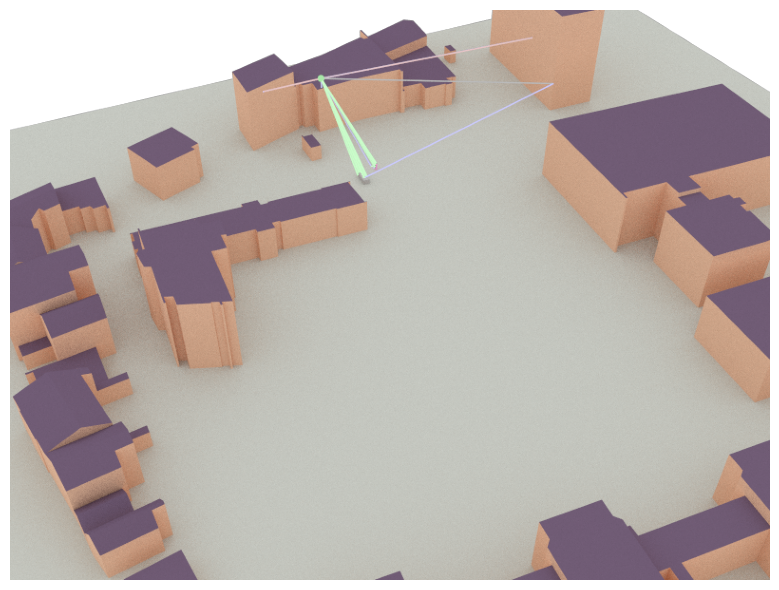

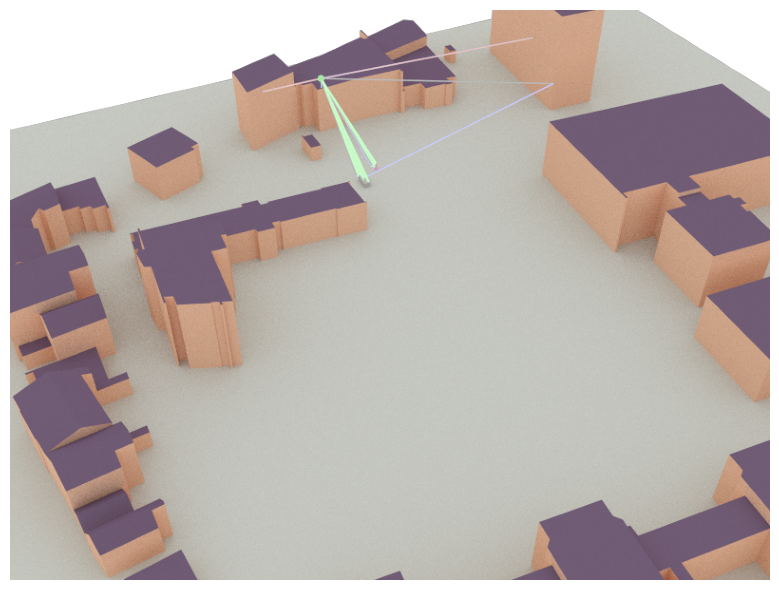

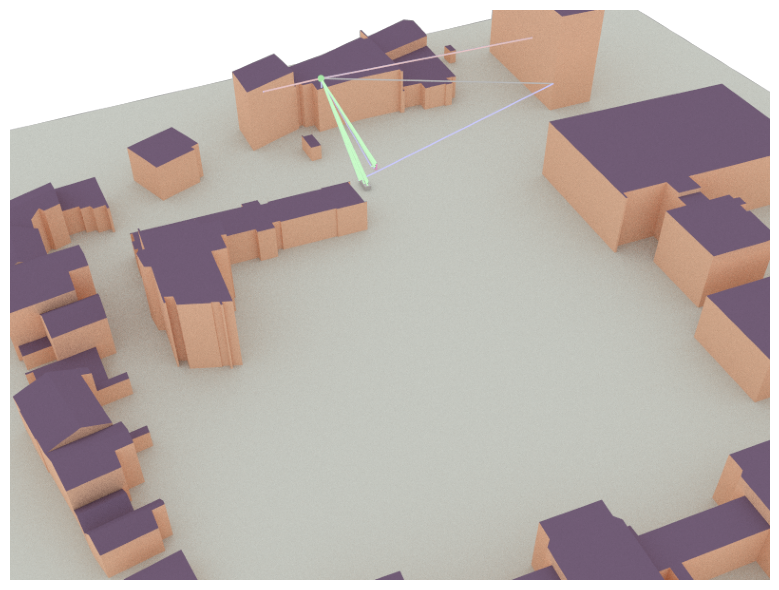

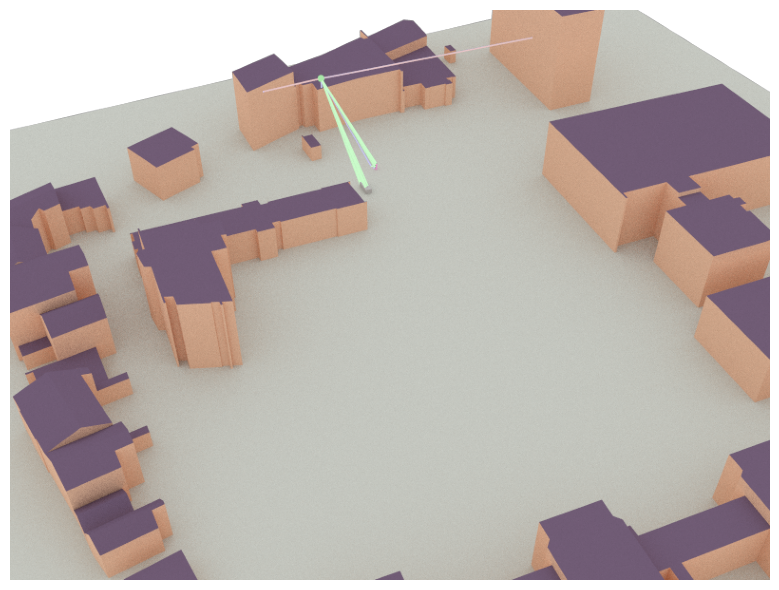

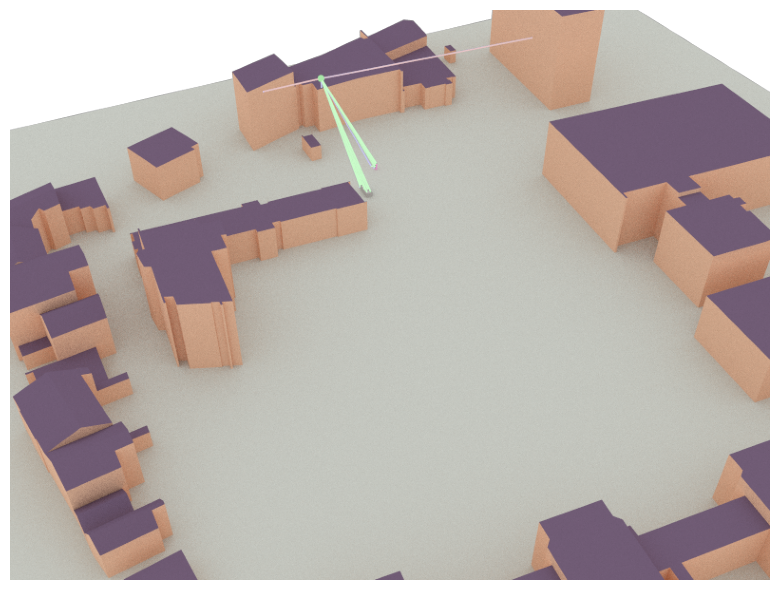

In [5]:
# Importowanie najwazniejszych bibliotek
%matplotlib inline
import importlib

import matplotlib.pyplot as plt
import numpy as np

# Importowanie najwazniejszych komponentow Sionna RT
from sionna.rt import Camera, PathSolver
from sionna_env import setup_scene
import ofdm_config as cfg
importlib.reload(cfg)

my_cam = Camera(position=[-100, -140, 150.0],
                look_at=[-40, -20, 30])

scene_file = "./OpenStreetMap/kampus_AGH_doppler/Kampus_AGH_B9_doppler.xml"

scene, tx, rx = setup_scene(scene_file, cfg.fc, cfg.rx_rows, cfg.rx_cols)

samochod = scene.get("Samochod_001")

p_solver = PathSolver()

# Konfiguracja ruchu
samochod_velocity = np.array([-5, -15, 0.0])  # Prędkość samochodu (m/s)
samochod.velocity = samochod_velocity

displacement_vec = samochod_velocity * 0.1
num_steps = 5

historia_taps = []

# Symulacja ruchu samochodu
for i in range(num_steps):
    
    paths = p_solver(scene=scene,
                 max_depth=3,
                 samples_per_src=500_000,
                 los=True,
                 specular_reflection=True,
                 diffuse_reflection=True,
                 refraction=True,
                 synthetic_array=False,
                 seed=67)

    a, tau = paths.taps(bandwidth=cfg.bandwidth,
                 num_time_steps=cfg.num_symbols,
                 sampling_frequency=cfg.ofdm_symbol_rate,
                 l_min = -6,
                 l_max = 100)

    historia_taps.append((a.numpy(), tau.numpy()))
    
    # Renderowanie Mapy - opcjonalnie można odkomentować poniższe linie, aby zobaczyć wizualizację sceny
    scene.render(camera=my_cam, 
                 paths=paths, 
                 rm_show_color_bar=True,
                 rm_vmax=-40, 
                 rm_vmin=-120,
                 resolution=(800, 600)) 

    # ruch samochodu
    samochod.position = samochod.position + displacement_vec

np.save("historia_taps.npy", historia_taps, allow_pickle=True)